# Lab 2 — What Did the Campaign Deliver?
Name: Diana Kadina | Group: KM-43

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [2]:
import numpy as np

pd.set_option("display.width", 160)
for name, df in [("programs", programs), ("viewings", viewings), ("daily_weights", daily_weights),
                 ("viewer_attributes", viewer_attributes), ("attributes", attributes),
                 ("commercials", commercials), ("rate_card", rate_card)]:
    print(f"{name:18s} {df.shape}")

programs           (5841, 15)
viewings           (1001885, 9)
daily_weights      (407561, 4)
viewer_attributes  (104679, 3)
attributes         (58, 5)
commercials        (167720, 9)
rate_card          (81, 8)


Preparation (same as in Lab 1): decode sex and age of every person, keep only persons R and L,
and compute each person's monthly weight (average weight over the days they were in-tab).

In [3]:
va = viewer_attributes.merge(attributes, on="attr_id", how="left")
rtype = va[va["attr_group"] == "Respondent type"].set_index("respondent_id")["attr_name"].str[0]
persons = pd.DataFrame({"resp_type": rtype[rtype.isin(["R", "L"])]})
persons["sex"] = va[va["attr_group"] == "Sex"].set_index("respondent_id")["attr_name"]
persons["age"] = va[va["attr_id"] == 300].set_index("respondent_id")["value"]

dw_p = daily_weights[daily_weights["resp_type"].isin(["R", "L"])].copy()
dw_p["broadcast_date"] = pd.to_datetime(dw_p["broadcast_date"])
month_w = dw_p.groupby("respondent_id")["weight"].mean()
persons = persons[persons.index.isin(month_w.index)]   # in-tab at least once in October
persons["mw"] = month_w

# audiences used in this lab
AUD = {
    "P2+": persons.index,
    "A18-49": persons.index[persons["age"].between(18, 49)],
}
print({a: len(ids) for a, ids in AUD.items()})

# universe of every broadcast day for each audience (sum of in-tab weights)
universe = {a: dw_p[dw_p["respondent_id"].isin(ids)].groupby("broadcast_date")["weight"].sum()
            for a, ids in AUD.items()}
n_intab = dw_p.groupby("broadcast_date").size()   # persons in-tab per day (for Task 5)

pv = viewings[viewings["resp_type"].isin(["R", "L"])].copy()   # person sessions, no guests
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]
SMALL = ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]

{'P2+': 10210, 'A18-49': 4568}


## Task 1.1 — Size

In [4]:
print("Spots:", len(commercials))
print("Pods:", commercials["pod_id"].nunique())
print("Brands:", commercials["brand"].nunique())
print("Categories:", commercials["category"].nunique())
brand_a = commercials[commercials["brand"] == "BRAND_A"].copy()
print("BRAND_A spots:", len(brand_a))
brand_a.groupby("network_code").size().rename("BRAND_A spots").to_frame().T

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


network_code,ABC,BRAVO,CBS,FNC,FOOD,FOX,FX,HGTV,HIST,NBC
BRAND_A spots,29,33,22,40,33,13,38,39,37,16


## Task 1.2 — Ad load

In [5]:
ads = commercials.copy()
ads["hour"] = ads["start_ts"].dt.floor("h")   # clock hour the spot starts in
per_hour = ads.groupby(["network_code", "hour"])["length_sec"].sum() / 60   # ad minutes in each hour
load = per_hour.groupby("network_code").agg(["mean", "count"])
load.columns = ["Ad minutes per hour", "Hours with ads"]
load["Hours in October"] = 31 * 24
load = load.sort_values("Ad minutes per hour", ascending=False)
print(load.round(1).to_string())
print("Heaviest ad load:", load["Ad minutes per hour"].idxmax())

              Ad minutes per hour  Hours with ads  Hours in October
network_code                                                       
FNC                          15.6             743               744
BRAVO                        13.4             623               744
HGTV                         13.3             621               744
HIST                         13.2             622               744
FOOD                         13.1             620               744
FX                           12.9             621               744
CBS                          12.1             427               744
ABC                          11.8             349               744
NBC                          11.8             299               744
FOX                          11.8             196               744
Heaviest ad load: FNC


In [6]:
# which hours of the broadcast networks have no national ads: what airs there?
tel_with_ads = set(commercials["telecast_id"])
bc = programs[programs["network_type"] == "broadcast"].copy()
bc["has_ads"] = bc["telecast_id"].isin(tel_with_ads)
no_ads = bc[~bc["has_ads"]]
print("Broadcast telecasts without national ads, by program type (hours):")
print((no_ads.groupby("program_type")["duration_min"].sum() / 60).round(0).sort_values(ascending=False).to_string())

Broadcast telecasts without national ads, by program type (hours):
program_type
local        1845.0
special         5.0
game show       0.0
news            0.0
reality         0.0
series          0.0


**Answer:** The heaviest ad load is on Fox News: 15.6 ad minutes per hour, and it has national ads in 743 of
744 hours of October. The cable networks carry about 13 minutes per hour, the broadcast networks about 12.
But the broadcast networks have national ads only in 196 (FOX) to 427 (CBS) hours. The rest of the time is
local / syndicated programming (about 1,845 hours on the four networks): in those hours the network gives the
time to its local stations, and the stations sell the breaks to local advertisers, so there are no national
commercials in our log. FOX has the fewest hours with ads because as a network it only programs prime time
and sports. A few more hours without ads are paid programming and the vice-presidential debate.

## Task 1.3 — Price everything

In [7]:
spots = commercials.merge(programs[["telecast_id", "program_name"]], on="telecast_id", how="left")
rc = rate_card.copy()

# 1) program rows win: match on network + program name
prog_rows = rc[rc["program_name"].notna() & (rc["program_name"] != "")]
spots = spots.merge(prog_rows[["network_code", "program_name", "daypart", "cost_30s_usd"]],
                    on=["network_code", "program_name"], how="left")
spots["row_type"] = np.where(spots["daypart"].notna(), "program", None)

# 2) the rest: time rows, by broadcast weekday and minutes since 06:00
def to_min(hhmm):
    h, m = map(int, hhmm.split(":"))
    return h * 60 + m - 360

time_rows = rc[rc["program_name"].isna() | (rc["program_name"] == "")].copy()
time_rows["start_m"] = time_rows["start_time"].map(to_min)
time_rows["end_m"] = time_rows["end_time"].map(to_min)

shifted = spots["start_ts"] - pd.Timedelta(hours=6)
spots["bweekday"] = shifted.dt.dayofweek
spots["bminute"] = shifted.dt.hour * 60 + shifted.dt.minute

# one row per (time row, weekday), so we can join on the weekday directly
tr = time_rows.explode("weekdays").rename(columns={"weekdays": "bweekday"})
tr["bweekday"] = tr["bweekday"].astype(int)

todo = spots[spots["daypart"].isna()].reset_index()
cand = todo[["index", "network_code", "bweekday", "bminute"]].merge(
    tr[["network_code", "bweekday", "daypart", "start_m", "end_m", "cost_30s_usd"]],
    on=["network_code", "bweekday"])
cand = cand[(cand["start_m"] <= cand["bminute"]) & (cand["bminute"] < cand["end_m"])]
print("Spots matched to more than one time row:", cand["index"].duplicated().sum())
cand = cand.set_index("index")
spots.loc[cand.index, "daypart"] = cand["daypart"]
spots.loc[cand.index, "cost_30s_usd"] = cand["cost_30s_usd"]
spots.loc[cand.index, "row_type"] = "time"

spots["cost"] = spots["cost_30s_usd"] * spots["length_sec"] / 30   # :15 = half, :60 = double
print("Spots without a price:", spots["cost"].isna().sum())

value = spots.groupby("network_code").agg(
    value=("cost", "sum"),
    from_programs=("cost", lambda c: c[spots.loc[c.index, "row_type"] == "program"].sum()))
value["Rate-card value (USD M)"] = value["value"] / 1e6
value["Share from program rows"] = value["from_programs"] / value["value"]
value = value[["Rate-card value (USD M)", "Share from program rows"]].sort_values("Rate-card value (USD M)", ascending=False)
value["Rate-card value (USD M)"] = value["Rate-card value (USD M)"].round(1)
value["Share from program rows"] = value["Share from program rows"].round(3)
print(value.to_string())
print("Total (USD M):", round(value["Rate-card value (USD M)"].sum(), 1))

Spots matched to more than one time row: 0
Spots without a price: 0
              Rate-card value (USD M)  Share from program rows
network_code                                                  
CBS                             818.8                    0.230
NBC                             724.3                    0.342
ABC                             708.8                    0.432
FOX                             696.2                    0.835
FNC                             315.8                    0.000
HGTV                             58.1                    0.000
FX                               42.5                    0.000
FOOD                             42.1                    0.000
HIST                             40.1                    0.000
BRAVO                            25.3                    0.000
Total (USD M): 3472.0


## Task 2.1 — Delivery

In [8]:
camp = spots[spots["brand"] == "BRAND_A"].copy()
camp["bdate"] = (camp["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()

# exposures: a person saw a spot if session start <= spot start < session end on that network
rows = []
for net, sp in camp.groupby("network_code"):
    s_net = pv[pv["network_code"] == net]
    for _, spot in sp.iterrows():
        seen = s_net[(s_net["start_ts"] <= spot["start_ts"]) & (spot["start_ts"] < s_net["end_ts"])]
        for rid in seen["respondent_id"].unique():
            rows.append((spot["ad_airing_id"], rid))
exp = pd.DataFrame(rows, columns=["ad_airing_id", "respondent_id"])
exp = exp.merge(camp[["ad_airing_id", "network_code", "bdate", "cost"]], on="ad_airing_id")
# weight of the person on the spot's broadcast day
exp = exp.merge(dw_p[["respondent_id", "broadcast_date", "weight"]],
                left_on=["respondent_id", "bdate"], right_on=["respondent_id", "broadcast_date"], how="left")
print("Exposures:", len(exp), "| without a weight:", exp["weight"].isna().sum())

def delivery(aud):
    ids = AUD[aud]
    e = exp[exp["respondent_id"].isin(ids)]
    imp = e.groupby("ad_airing_id")["weight"].sum().reindex(camp["ad_airing_id"], fill_value=0)
    univ = camp.set_index("ad_airing_id")["bdate"].map(universe[aud])
    rating = imp / univ * 100
    reached = e["respondent_id"].unique()
    reach = persons.loc[reached, "mw"].sum() / persons.loc[ids, "mw"].sum() * 100
    grps = rating.sum()
    return {"imp": imp, "rating": rating, "grps": grps, "reach": reach, "freq": grps / reach}

d = {a: delivery(a) for a in AUD}
camp = camp.set_index("ad_airing_id")
for a in AUD:
    camp[f"imp {a}"] = d[a]["imp"]
    camp[f"rating {a}"] = d[a]["rating"]

print("P2+ impressions (M):", f'{d["P2+"]["imp"].sum() / 1e6:.1f}')
print("P2+ GRPs:", f'{d["P2+"]["grps"]:.1f}')
print("P2+ reach (%):", f'{d["P2+"]["reach"]:.1f}')
print("P2+ average frequency:", f'{d["P2+"]["freq"]:.1f}')
print("A18-49 impressions (M):", f'{d["A18-49"]["imp"].sum() / 1e6:.1f}')
print("A18-49 GRPs:", f'{d["A18-49"]["grps"]:.1f}')
print("A18-49 reach (%):", f'{d["A18-49"]["reach"]:.1f}')
print("A18-49 average frequency:", f'{d["A18-49"]["freq"]:.1f}')

Exposures: 11289 | without a weight: 0
P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

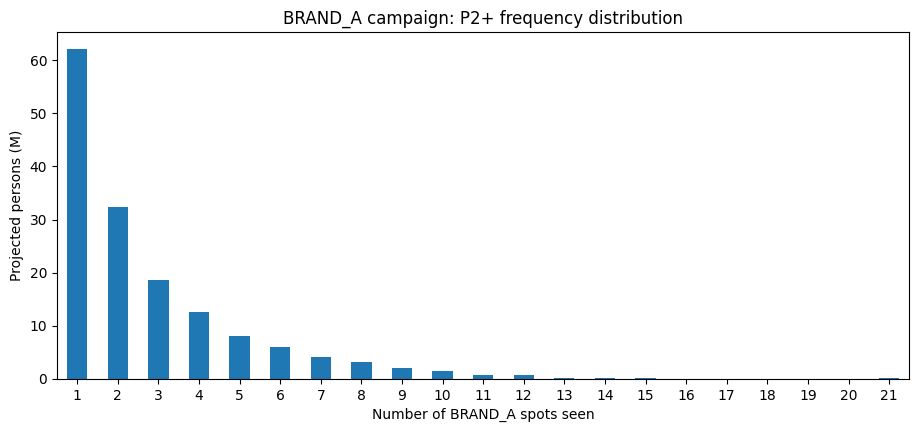

Persons reached (M): 152.3
Median frequency (weighted): 2
Share of persons reached who saw 5+: 0.175
Share of impressions at 5+ exposures: 0.444


In [9]:
freq = exp.groupby("respondent_id")["ad_airing_id"].nunique().rename("spots_seen").to_frame()
freq["mw"] = persons["mw"].reindex(freq.index)
dist = freq.groupby("spots_seen")["mw"].sum() / 1e6
dist = dist.reindex(range(1, dist.index.max() + 1), fill_value=0)

ax = dist.plot(kind="bar", figsize=(11, 4.5), color="tab:blue")
ax.set_xlabel("Number of BRAND_A spots seen")
ax.set_ylabel("Projected persons (M)")
ax.set_title("BRAND_A campaign: P2+ frequency distribution")
plt.xticks(rotation=0)
plt.show()

exp["spots_seen"] = exp["respondent_id"].map(freq["spots_seen"])
share5 = exp.loc[exp["spots_seen"] >= 5, "weight"].sum() / exp["weight"].sum()
print("Persons reached (M):", f'{freq["mw"].sum() / 1e6:.1f}')
f_sorted = freq.sort_values("spots_seen")
half = np.searchsorted(f_sorted["mw"].cumsum(), f_sorted["mw"].sum() / 2)
print("Median frequency (weighted):", f_sorted["spots_seen"].iloc[half])
print("Share of persons reached who saw 5+:", f'{freq.loc[freq["spots_seen"] >= 5, "mw"].sum() / freq["mw"].sum():.3f}')
print("Share of impressions at 5+ exposures:", f"{share5:.3f}")

**Answer:** No. The average frequency is 3.0, but the weighted median is 2, and the biggest group of people
saw the ad only once. At the same time the 17.5% of reached persons who saw 5 or more spots received 44.4% of all
impressions. So the campaign hit a small group of heavy TV viewers again and again, while most people saw it once or twice. "The average viewer saw it 3 times"
describes almost nobody.

## Task 2.3 — On target?

In [10]:
target_univ_share = persons.loc[AUD["A18-49"], "mw"].sum() / persons["mw"].sum()
print("A18-49 share of all persons:", f"{target_univ_share:.3f}")
print("Share of impressions on A18-49:", f'{d["A18-49"]["imp"].sum() / d["P2+"]["imp"].sum():.3f}')

by_net = camp.groupby("network_code").agg(spots=("cost", "size"),
                                          imp_p2=("imp P2+", "sum"), imp_t=("imp A18-49", "sum"))
by_net["Share of campaign impressions"] = by_net["imp_p2"] / by_net["imp_p2"].sum()
by_net["A18-49 share of impressions"] = by_net["imp_t"] / by_net["imp_p2"]
by_net["Index vs population"] = (by_net["A18-49 share of impressions"] / target_univ_share * 100).round(0)
print(by_net[["spots", "Share of campaign impressions", "A18-49 share of impressions", "Index vs population"]]
      .sort_values("Share of campaign impressions", ascending=False).round(3).to_string())

A18-49 share of all persons: 0.422
Share of impressions on A18-49: 0.194
              spots  Share of campaign impressions  A18-49 share of impressions  Index vs population
network_code                                                                                        
ABC              29                          0.225                        0.180                 43.0
CBS              22                          0.212                        0.154                 36.0
FOX              13                          0.182                        0.242                 57.0
FNC              40                          0.138                        0.047                 11.0
NBC              16                          0.099                        0.189                 45.0
HGTV             39                          0.059                        0.306                 73.0
HIST             37                          0.029                        0.202                 48.0
FOOD             3

**Answer:** Only 19.4% of the impressions landed on adults 18-49, while they are 42.2% of all persons, so the
plan strongly under-delivered against its target (index about 46 vs population). The reason is where the spots
ran: the five big networks give 86% of the impressions and all of them have old audiences. The worst is Fox News:
40 spots and 13.8% of all impressions, but only 4.7% of them are A18-49 (index 11). CBS (index 36), ABC (43) and
NBC (45) are also far below. Only FX (index 154) and Bravo (131) over-deliver on the target, but together they
bring about 3% of the impressions, so they can't fix the total.

## Task 3.1 — Cost

In [11]:
cost = camp["cost"].sum()
print("Campaign cost (USD):", round(cost))
print("P2+ CPM (USD):", f'{cost / (d["P2+"]["imp"].sum() / 1000):.2f}')
print("P2+ CPP (USD):", round(cost / d["P2+"]["grps"]))
print("A18-49 CPM (USD):", f'{cost / (d["A18-49"]["imp"].sum() / 1000):.2f}')
print("A18-49 CPP (USD):", round(cost / d["A18-49"]["grps"]))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [12]:
net = camp.groupby("network_code").agg(spots=("cost", "size"), cost=("cost", "sum"),
                                       imp_p2=("imp P2+", "sum"), imp_t=("imp A18-49", "sum"))
net["Cost (USD)"] = net["cost"].round(0).astype(int)
net["Share of budget"] = (net["cost"] / net["cost"].sum()).round(3)
net["P2+ impressions (M)"] = (net["imp_p2"] / 1e6).round(1)
net["A18-49 impressions (M)"] = (net["imp_t"] / 1e6).round(1)
net["P2+ CPM (USD)"] = (net["cost"] / (net["imp_p2"] / 1000)).round(2)
net["A18-49 CPM (USD)"] = (net["cost"] / (net["imp_t"] / 1000)).round(2)
net = net.drop(columns=["cost", "imp_p2", "imp_t"]).sort_values("Cost (USD)", ascending=False)
net

,spots,Cost (USD),Share of budget,P2+ impressions (M),A18-49 impressions (M),P2+ CPM (USD),A18-49 CPM (USD)
network_code,,,,,,,
FOX,13,2434700,0.328,76.3,18.4,31.93,132.03
ABC,29,1625700,0.219,94.2,17.0,17.26,95.69
CBS,22,1488700,0.201,89.0,13.7,16.73,108.72
NBC,16,796800,0.107,41.4,7.8,19.23,101.72
FNC,40,526300,0.071,57.8,2.7,9.11,193.70
HGTV,39,230000,0.031,24.7,7.6,9.33,30.45
FOOD,33,96620,0.013,9.5,3.0,10.19,32.29
FX,38,92200,0.012,8.5,5.6,10.82,16.61
HIST,37,79640,0.011,12.3,2.5,6.46,32.05


**Answer:** Almost all the money went to the big networks: 92.6% of the budget. FOX alone took 32.8% for only 13
spots, because its spots were in sports (MLB postseason / World Series, NFL, college football), which are sold by
program rows at very high prices. ABC (21.9%) and CBS (20.1%) are next. For the target the big networks are
expensive: A18-49 CPM is $96-132 on ABC, NBC, CBS and FOX and $194 on Fox News. The cheapest way to reach A18-49
was FX ($16.61) and Bravo ($17.61), then HGTV, History and Food Network (about $30-32), so 5-10 times cheaper than
the big networks, although each of their spots reaches far fewer people.

## Task 3.3 — Guarantee

In [13]:
GUARANTEE = 150
grps_p2 = d["P2+"]["grps"]
owed = max(0, GUARANTEE - grps_p2)
cpp_p2 = cost / grps_p2
print("Delivered P2+ GRPs:", f"{grps_p2:.1f}")
print("Guarantee met:", grps_p2 >= GUARANTEE)
print("Make-good GRPs owed:", f"{owed:.1f}")
print("Value of make-goods (USD):", round(owed * cpp_p2))

Delivered P2+ GRPs: 132.0
Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [14]:
def reach_of(spot_ids, aud="P2+"):
    ids = AUD[aud]
    who = exp.loc[exp["ad_airing_id"].isin(spot_ids) & exp["respondent_id"].isin(ids), "respondent_id"].unique()
    return persons.loc[who, "mw"].sum() / persons.loc[ids, "mw"].sum() * 100, set(who)

big_ids = camp.index[camp["network_code"].isin(BIG)]
small_ids = camp.index[camp["network_code"].isin(SMALL)]
r_big, who_big = reach_of(big_ids)
r_small, who_small = reach_of(small_ids)
r_all, who_all = reach_of(camp.index)
both = list(who_big & who_small)
overlap = persons.loc[both, "mw"].sum() / persons["mw"].sum() * 100
overlap_ind = r_big * r_small / 100
added = r_all - r_big
cost_big = camp.loc[big_ids, "cost"].sum()
cost_small = camp.loc[small_ids, "cost"].sum()

print("Reach, big networks (%):", f"{r_big:.1f}")
print("Reach, small networks (%):", f"{r_small:.1f}")
print("Reach, whole campaign (%):", f"{r_all:.1f}")
print("Overlap (%):", f"{overlap:.1f}")
print("Overlap if independent (%):", f"{overlap_ind:.1f}")
print("Reach added by small networks (points):", f"{added:.1f}")
print("Cost per added reach point, small (USD):", round(cost_small / added))
print("Cost per reach point, big (USD):", round(cost_big / r_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


In [15]:
# extra: how likely is a small-network viewer to be reached by the big networks?
print("Share of the small-network audience also reached by big networks:", f"{overlap / r_small:.3f}")
print("Share of all persons reached by big networks:", f"{r_big / 100:.3f}")
print("Big / small spots:", len(big_ids), "/", len(small_ids))
print("Big / small cost (USD):", round(cost_big), "/", round(cost_small))

Share of the small-network audience also reached by big networks: 0.702
Share of all persons reached by big networks: 0.398
Big / small spots: 120 / 180
Big / small cost (USD): 6872200 / 548070


**Answer:** Reach does not add up because the same people watch both groups of networks: 39.8% + 12.4% = 52.2%,
but the whole campaign reached only 43.5%, because 8.7% of persons were reached by both and are counted once.
If the two audiences were independent, the overlap would be 39.8% × 12.4% = 4.9%, so the real overlap is almost
twice as large. Of the people reached on the small networks, 70% were also reached by the big ones, while the big
networks reached only 40% of all persons. So small-network viewers are much more likely to be reached by the big
networks: people who watch a lot of TV watch many channels, and the light viewers we miss on the big networks
mostly don't watch HGTV or History either. The small networks added only 3.7 points of reach, but they were cheap:
about $149k per added point vs $172k per reach point on the big networks, and their audience is younger. So the
money was spent reasonably, even though most of their viewers had already been reached.

## Task 5 — How sure are we?

In [16]:
panel = exp.groupby("ad_airing_id")["respondent_id"].nunique().reindex(camp.index, fill_value=0)
camp["panelists"] = panel
p = camp["rating P2+"] / 100
n = camp["bdate"].map(n_intab)
camp["SE"] = np.sqrt(p * (1 - p) / n) * 100
camp["rel SE"] = camp["SE"] / camp["rating P2+"]   # undefined (NaN) for zero ratings
camp["group"] = np.where(camp["network_code"].isin(BIG), "big", "small")

t5 = camp.groupby("network_code").agg(spots=("panelists", "size"),
                                       median_panelists=("panelists", "median"),
                                       zero_panelists=("panelists", lambda x: (x == 0).sum()),
                                       median_rating=("rating P2+", "median"),
                                       median_rel_SE=("rel SE", "median"))
t5["group"] = np.where(t5.index.isin(BIG), "big", "small")
print(t5.sort_values(["group", "median_panelists"], ascending=[True, False]).round(3).to_string())

zero = camp["panelists"] == 0
print("Rating of the spots seen by no panelist:", camp.loc[zero, "rating P2+"].unique())

w1834 = persons.index[(persons["sex"] == "Female") & persons["age"].between(18, 34)]
seen_w = exp[exp["respondent_id"].isin(w1834)].groupby("ad_airing_id")["respondent_id"].nunique()
w_zero = (seen_w.reindex(camp.index, fill_value=0) == 0).sum()
print("W18-34 panelists in-tab at least once:", len(w1834))

print("Spots seen by no panelist:", int(zero.sum()))
print("Median relative SE, big networks:", f'{camp.loc[camp["group"] == "big", "rel SE"].median():.3f}')
print("Median relative SE, small networks:", f'{camp.loc[camp["group"] == "small", "rel SE"].median():.3f}')
print("W18-34 zero-cell spots:", int(w_zero))

              spots  median_panelists  zero_panelists  median_rating  median_rel_SE  group
network_code                                                                              
FOX              13             145.0               0          1.641          0.080    big
CBS              22              69.0               0          0.844          0.113    big
NBC              16              68.5               0          0.811          0.115    big
ABC              29              57.0               0          0.714          0.123    big
FNC              40              31.0               0          0.399          0.164    big
HGTV             39              11.0               0          0.119          0.301  small
FX               38               5.5               4          0.055          0.423  small
FOOD             33               5.0               2          0.056          0.423  small
HIST             37               5.0               1          0.050          0.460  small

**Answer:** A rating of 0 does not mean that nobody in the US saw the spot: it means that none of the about
9,300 people in the panel saw it. One panelist stands for about 34,000 persons, so any spot with a smaller audience
than that can only get 0 or a jump to a few hundredths of a point. This happened to 10 spots, all on the small
networks, where the median spot was seen by only 3-11 panelists (vs 31-145 on the big networks). The median
relative error is 12% of the rating on the big networks and 42% on the small ones, and that's a lower bound,
because a weighted panel works like a smaller sample. For W18-34, 171 of the 300 spots were seen by no woman
18-34 in the panel. So I would tell the client that W18-34 ratings by spot cannot be reported reliably: most would
be 0 or based on 1-2 people. Instead I would report W18-34 for the whole campaign (GRPs and reach over the month),
by network, or for a wider audience like W18-49 or A18-49.

## Bonus

In [17]:
# A18-49 CPM by network and daypart (from the BRAND_A spots)
dp = camp.groupby(["network_code", "daypart"]).agg(spots=("cost", "size"), price_30s=("cost_30s_usd", "first"),
                                                    cost=("cost", "sum"), imp_t=("imp A18-49", "sum"),
                                                    imp_p2=("imp P2+", "sum"))
dp["A18-49 imp per spot"] = dp["imp_t"] / dp["spots"]
dp["P2+ imp per spot"] = dp["imp_p2"] / dp["spots"]
dp["A18-49 CPM (USD)"] = dp["cost"] / (dp["imp_t"] / 1000)
print(dp[dp["spots"] >= 5].sort_values("A18-49 CPM (USD)").head(8).round(1).to_string())

# take the 20 Fox News spots with the highest A18-49 CPM,
fnc = camp[camp["network_code"] == "FNC"].copy()
fnc["cpm_t"] = fnc["cost"] / (fnc["imp A18-49"] / 1000)
out = fnc.sort_values("cpm_t", ascending=False).head(20)
budget = out["cost"].sum()
# and buy FX Prime and Bravo Prime with the same money
fx = dp.loc[("FX", "Prime")]
br = dp.loc[("BRAVO", "Prime")]
n_fx, n_br = 14, 21
new_cost = n_fx * fx["price_30s"] + n_br * br["price_30s"]
add_t = n_fx * fx["A18-49 imp per spot"] + n_br * br["A18-49 imp per spot"]
add_p2 = n_fx * fx["P2+ imp per spot"] + n_br * br["P2+ imp per spot"]

imp_t_new = d["A18-49"]["imp"].sum() - out["imp A18-49"].sum() + add_t
cost_new = cost - budget + new_cost
print("Budget of the 20 FNC spots (USD):", round(budget), "| their A18-49 impressions (M):", f'{out["imp A18-49"].sum() / 1e6:.1f}')
print("New buy: FX Prime", n_fx, "+ Bravo Prime", n_br, "spots, cost (USD):", round(new_cost))
print("Expected A18-49 impressions added (M):", f"{add_t / 1e6:.1f}")
print("Bonus, A18-49 impressions (M), before", f'{d["A18-49"]["imp"].sum() / 1e6:.1f}', "after", f"{imp_t_new / 1e6:.1f}")
print("Bonus, A18-49 CPM (USD), before", f'{cost / (d["A18-49"]["imp"].sum() / 1000):.2f}', "after", f"{cost_new / (imp_t_new / 1000):.2f}")
print("P2+ GRPs change:", f'{(add_p2 - out["imp P2+"].sum()) / universe["P2+"].mean() * 100:.1f}')

                               spots  price_30s     cost    imp_t   imp_p2  A18-49 imp per spot  P2+ imp per spot  A18-49 CPM (USD)
network_code daypart                                                                                                               
FX           Daytime Movies       25     1100.0  27500.0  2311756  3627493              92470.2          145099.7              11.9
BRAVO        Weekend Marathon      6      870.0   5220.0   412179   800876              68696.5          133479.3              12.7
             Late Fringe           9      870.0   7830.0   512173   783331              56908.1           87036.8              15.3
             Daytime Rotator      12      580.0   6960.0   415604   934809              34633.7           77900.8              16.7
FX           Fringe                5     2900.0  14500.0   724736  1199543             144947.2          239908.6              20.0
             Prime                 6     8000.0  48000.0  2343170  3443583  

**Answer:** I would take the 20 Fox News spots with the highest A18-49 CPM (mostly Daytime News, Weekend and
Overnight; together $231,300 for only 0.3M A18-49 impressions) and spend the same money on 14 spots in FX Prime
($8,000 each) and 21 in Bravo Prime ($5,500 each), $227,500 in total. In our data these dayparts cost about $21-23
per thousand A18-49 impressions instead of $194 on Fox News, and one spot reaches 245-390 thousand A18-49 instead
of about 14 thousand. Using the average audience of the BRAND_A spots there, this adds about 10.6M A18-49
impressions (81.1M to 91.4M) and lowers the target CPM from $91.53 to about $81, and since FX and Bravo viewers
are younger and less often reached by the big networks, it should also add some A18-49 reach. The cost is about
1.4 P2+ GRPs, and the estimate is based on only 5-6 spots per daypart, so it is rough (see Task 5).